# Muon Angle Real Data -- Containment Split

Real-data (10% unblinded Run 2, 2.36e19 POT) counterpart of `muon_angle/Asimov_Containment_Studies.ipynb`, for the containment-split (contained/exiting) simultaneous fit in the muon angle with respect to the NuMI beam, $\cos\theta_\mu$. It reads the `RealData_Containment` outputs listed in `RunConfigs/muon_angle/RealData_Containment/RealData_Containment_instructions.md`. The structure follows `opening_angle/RealData_Containment_Studies.ipynb`.

**Likelihood:** `BarlowLLH` (not `PoissonLLH`), which accounts for the finite MC statistics. This is appropriate now that the data is real and not Asimov.

**Known gap, not introduced here:** `dataSetListConfig_RealData.yaml` does not define `ICARUS_NuMI_1muNp0pi_cosmics` and `_cosmics_sideband` (they are commented out), while the containment fitSampleSet's selection and sideband samples reference them. The same mismatch exists in the dpT, dalphaT and opening-angle real-data configurations, so the muon-angle setup inherits it.

**Binning:** truth binning is `binning_true_muon_angle.txt` (7 bins from -1 to 1, shared across all 4 samples). Reco binning is per channel: contained selection uses `binning_reco_leading_muon_angle_contained.txt` (18 bins), exiting selection uses `binning_reco_leading_muon_angle_exiting.txt` (14 bins), and both sidebands use their own 24-bin files. $\cos\theta_\mu$ is bounded to [-1, 1], so none of these binnings has an overflow bin and no bin is dropped when plotting (`remove_last_bin=False`).

**`cov_bin_range` -- expected from the Asimov muon-angle configuration, NOT YET VERIFIED on a real-data output file.** With no overflow bin, each block of the full covariance matrix has the width of its binning: 18 + 14 + 24 + 24 = 80 rows, so the slices are (0,18), (18,32), (32,56), (56,80). Run the sanity-check cell below on the real-data prefit file first. If it reports a mismatch, edit the `cov_bin_range` values in the four sample sections.

**Not included here:** the bespoke mirror-dial systematic studies from `dpT/RealData_Studies.ipynb` (VecFFCCQEshape, DecayAngMEC, Theta_Delta2Npi grid fits and LLH scans) are not ported. They are specialized real-data diagnostics and would need their own adaptation.


In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Binning Sanity Check

Compares the expected covariance block widths with the actual contents of the real-data pre-fit toy-generator file. Every line should end in `OK`.


In [2]:
import uproot

PREFIT_FILE = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/prefit_real_containment_muon_angle.root'
SAMPLES = {
    'selection_contained': 'selection_reco_muon_angle_contained',
    'selection_exiting':   'selection_reco_muon_angle_exiting',
    'sideband_contained':  'sideband_reco_muon_angle_contained',
    'sideband_exiting':    'sideband_reco_muon_angle_exiting',
}
COV_RANGE = {
    'selection_contained': (0, 18),
    'selection_exiting':   (18, 32),
    'sideband_contained':  (32, 56),
    'sideband_exiting':    (56, 80),
}

f_pre = uproot.open(PREFIT_FILE)
cov_full = f_pre['toyGen/matrices/covarianceMatrix_TH2D'].values()
expected_rows = max(hi for _, hi in COV_RANGE.values())
print(f'covarianceMatrix_TH2D shape: {cov_full.shape}  (expected {expected_rows} x {expected_rows})  ->',
      'OK' if cov_full.shape == (expected_rows, expected_rows) else 'MISMATCH')

for key, sample in SAMPLES.items():
    lo, hi = COV_RANGE[key]
    nbins = None
    for cat in range(11):
        path = f'toyGen/plots/histograms/{sample} (pre-fit)/reco_leading_muon_cos_theta_mu/category/{cat}/MC_TH1D'
        try:
            nbins = len(f_pre[path].values())
            break
        except KeyError:
            continue
    status = 'OK' if nbins == hi - lo else 'MISMATCH'
    print(f'{sample:<36} category-histogram bins: {nbins}  |  COV_RANGE width: {hi - lo}  ->  {status}')


covarianceMatrix_TH2D shape: (80, 80)  (expected 80 x 80)  -> OK
selection_reco_muon_angle_contained  category-histogram bins: 18  |  COV_RANGE width: 18  ->  OK
selection_reco_muon_angle_exiting    category-histogram bins: 14  |  COV_RANGE width: 14  ->  OK
sideband_reco_muon_angle_contained   category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
sideband_reco_muon_angle_exiting     category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK


## Selection - Contained

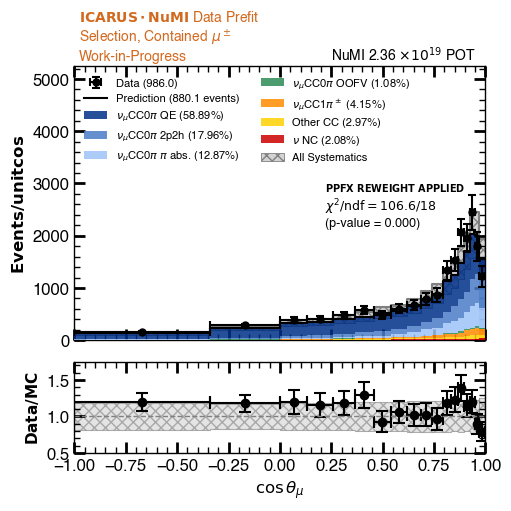

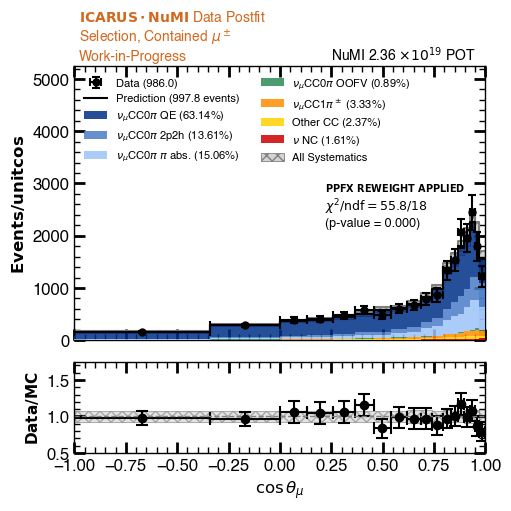

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/prefit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='selection_reco_muon_angle_contained',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(0, 18),  # selection contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Prefits', save_name='prefit_muon_angle_selection_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/postfit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='selection_reco_muon_angle_contained',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(0, 18),  # selection contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Postfits', save_name='postfit_muon_angle_selection_contained'
)

## Selection - Exiting

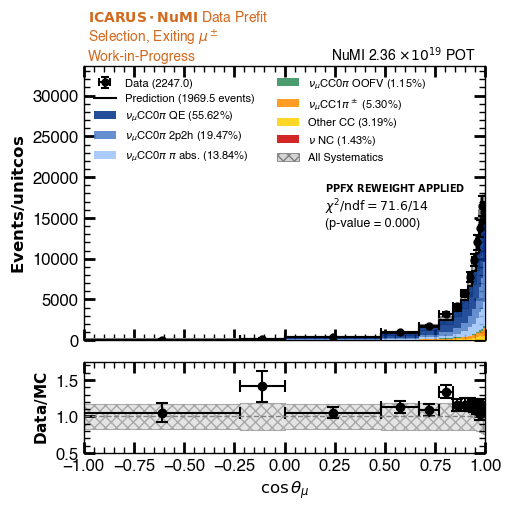

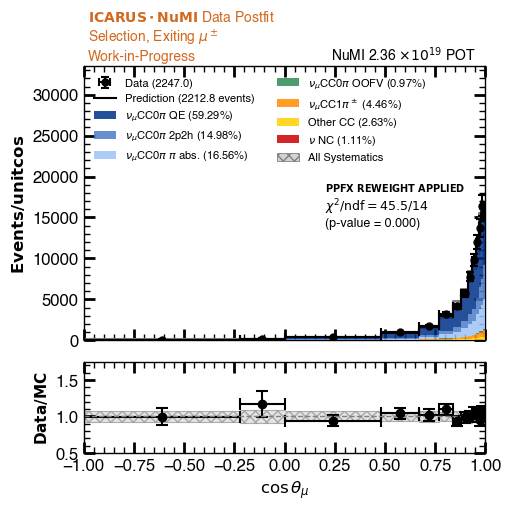

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/prefit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='selection_reco_muon_angle_exiting',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(18, 32),  # selection exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Prefits', save_name='prefit_muon_angle_selection_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/postfit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='selection_reco_muon_angle_exiting',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(18, 32),  # selection exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Postfits', save_name='postfit_muon_angle_selection_exiting'
)

## Sideband - Contained

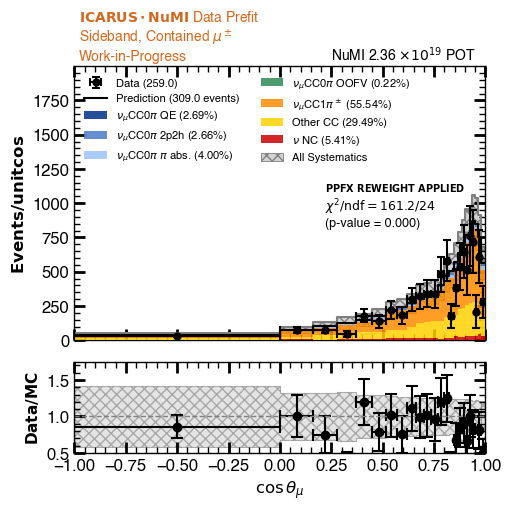

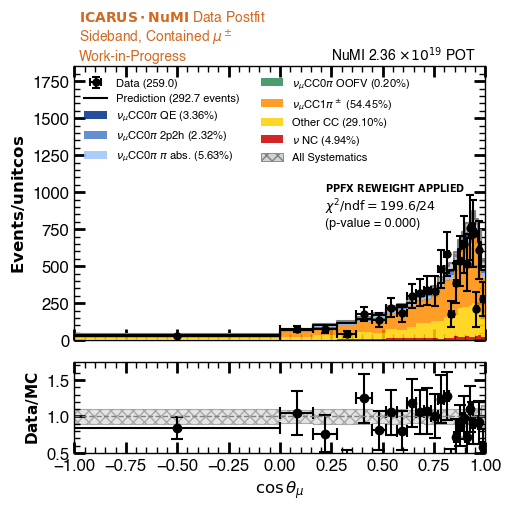

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/prefit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='sideband_reco_muon_angle_contained',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(32, 56),  # sideband contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Prefits', save_name='prefit_muon_angle_sideband_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/postfit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='sideband_reco_muon_angle_contained',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(32, 56),  # sideband contained: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Postfits', save_name='postfit_muon_angle_sideband_contained'
)

## Sideband - Exiting

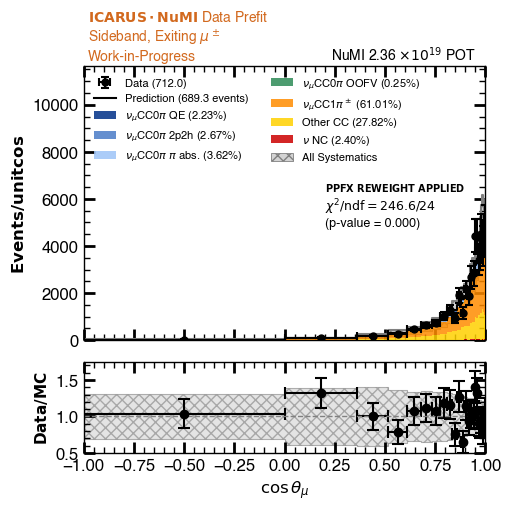

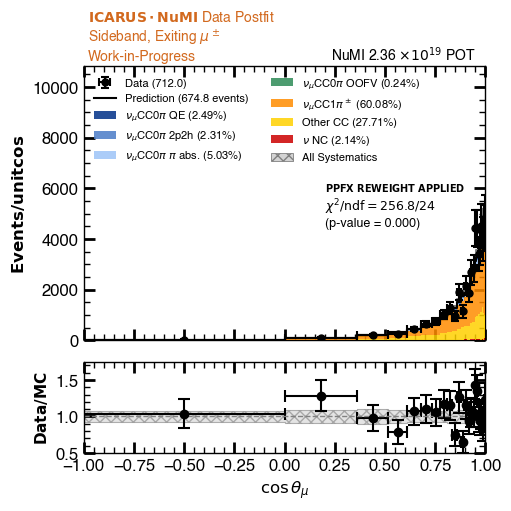

In [6]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/prefit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='sideband_reco_muon_angle_exiting',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(56, 80),  # sideband exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Prefits', save_name='prefit_muon_angle_sideband_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/postfit_real_containment_muon_angle.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    sample_name='sideband_reco_muon_angle_exiting',
    is_data=True,
    variable_name='reco_leading_muon_cos_theta_mu',
    cov_bin_range=(56, 80),  # sideband exiting: block width = number of bins (no overflow bin). Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$\cos\theta_{\mu}$',
    ylabel=r'$\mathbf{Events / unit cos}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/muon_angle/RealData_Containment/Postfits', save_name='postfit_muon_angle_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `real_containment_XSec_muon_angle.root`. It uses the true-level `True_muon_angle_XS` sample with 7 truth bins, which the reco-level containment split does not change. $\cos\theta_\mu$ is dimensionless, so the units are cm$^2$/Ar, scaled by $10^{40}$, with no unit conversion. The truth binning has no overflow bin (`remove_last_bin=False`).


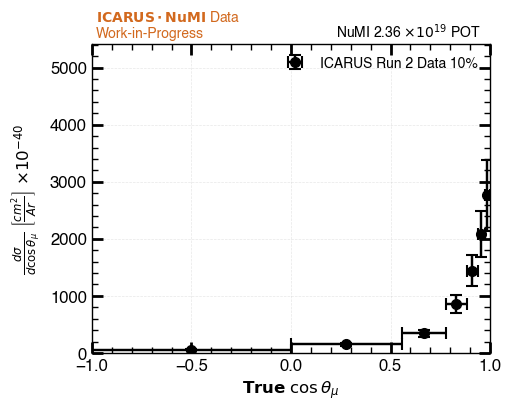

In [7]:
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/muon_angle/RealData_Containment/real_containment_XSec_muon_angle.root',
        is_cross_section = True,
        hist_path="calcXsec/histograms/True_muon_angle_XS_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\cos\theta_{\mu}$',
        ylabel=r'$\frac{d\sigma}{d\cos\theta_{\mu}}$ $\left[\frac{cm^2}{Ar}\right]$ $\times 10^{-40}$',
        bin_edges_labels=[-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
        remove_last_bin=False,
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label="ICARUS Run 2 Data 10%",
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        scaling_power_of_10=1e40
)
save_fig(fig_xs, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           4.041305e+01
  0.0000 – 0.5566           1.293836e+02
  0.5566 – 0.7787           3.165054e+02
  0.7787 – 0.8823           6.511265e+02
  0.8823 – 0.9389           1.171309e+03
  0.9389 – 0.9734           1.846366e+03
  0.9734 – 1.0000           2.428526e+03

χ² / Ndof = 6.4 / 7 = 0.917
p-value = 0.492


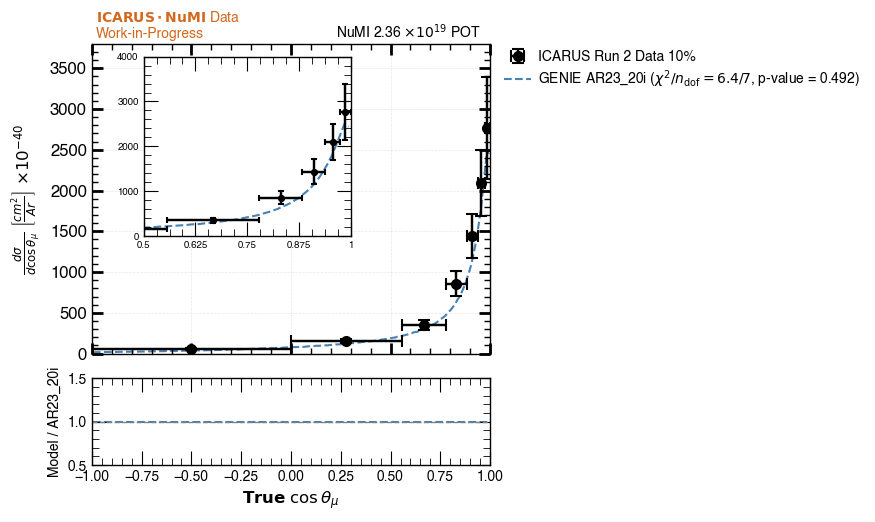

In [8]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wGENIE')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           4.240712e+01
  0.0000 – 0.5566           1.372176e+02
  0.5566 – 0.7787           3.368391e+02
  0.7787 – 0.8823           6.950213e+02
  0.8823 – 0.9389           1.264241e+03
  0.9389 – 0.9734           2.027417e+03
  0.9734 – 1.0000           2.739798e+03

χ² / Ndof = 3.4 / 7 = 0.481
p-value = 0.849


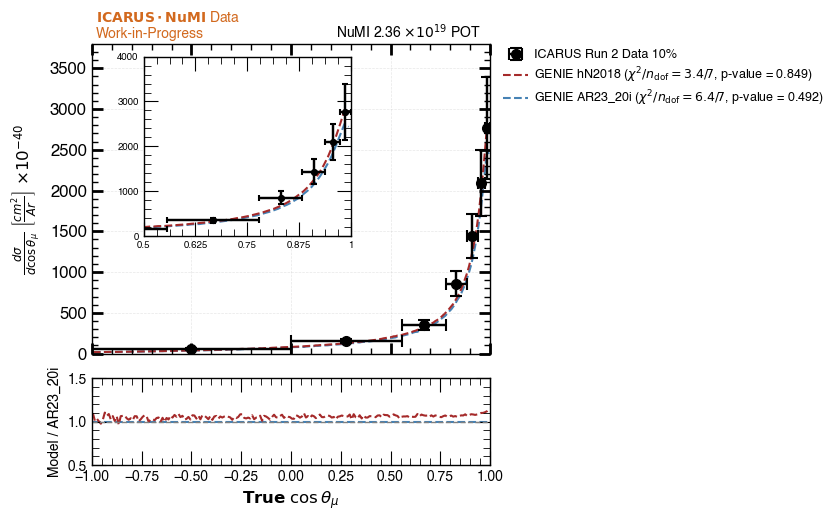

In [9]:
# Overlay GENIE hN2018 with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE hN2018',
    color               = 'brown',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wGENIE_hN2018')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           4.865696e+01
  0.0000 – 0.5566           1.483813e+02
  0.5566 – 0.7787           3.571538e+02
  0.7787 – 0.8823           7.196044e+02
  0.8823 – 0.9389           1.262187e+03
  0.9389 – 0.9734           1.920306e+03
  0.9734 – 1.0000           2.451582e+03

χ² / Ndof = 2.1 / 7 = 0.296
p-value = 0.956


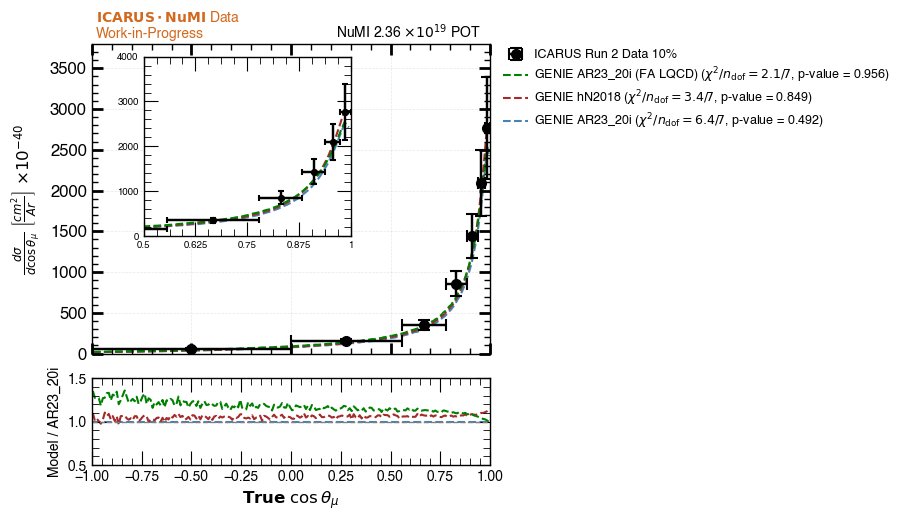

In [10]:
# Overlay GENIE LQCD with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i (FA LQCD)',
    color               = 'green',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wGENIE_LQCD')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           5.697925e+01
  0.0000 – 0.5566           1.695168e+02
  0.5566 – 0.7787           4.023221e+02
  0.7787 – 0.8823           8.040182e+02
  0.8823 – 0.9389           1.392916e+03
  0.9389 – 0.9734           2.093441e+03
  0.9734 – 1.0000           2.572022e+03

χ² / Ndof = 1.3 / 7 = 0.185
p-value = 0.989


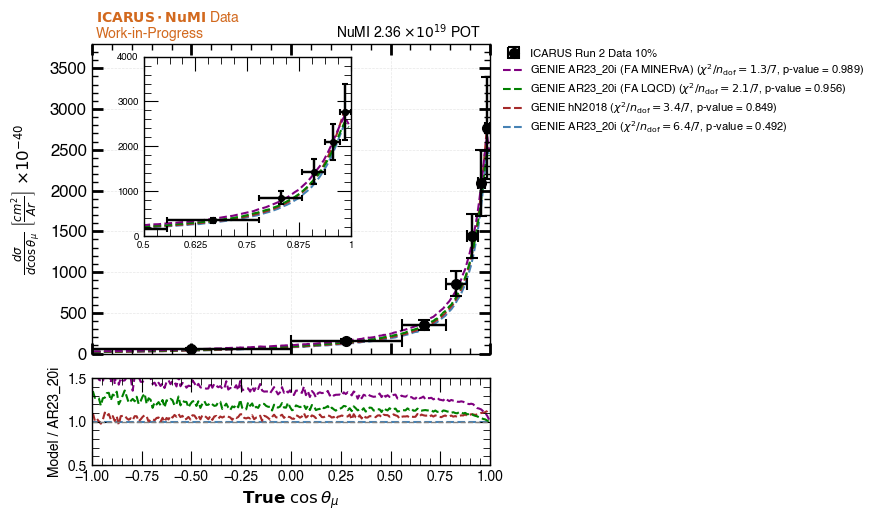

In [11]:
# Overlay GENIE MINERvA with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i (FA MINERvA)',
    color               = 'purple',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wGENIE_MINERvA')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           4.198570e+01
  0.0000 – 0.5566           1.403126e+02
  0.5566 – 0.7787           3.407125e+02
  0.7787 – 0.8823           7.042324e+02
  0.8823 – 0.9389           1.305706e+03
  0.9389 – 0.9734           2.078690e+03
  0.9734 – 1.0000           2.584219e+03

χ² / Ndof = 3.1 / 7 = 0.437
p-value = 0.880


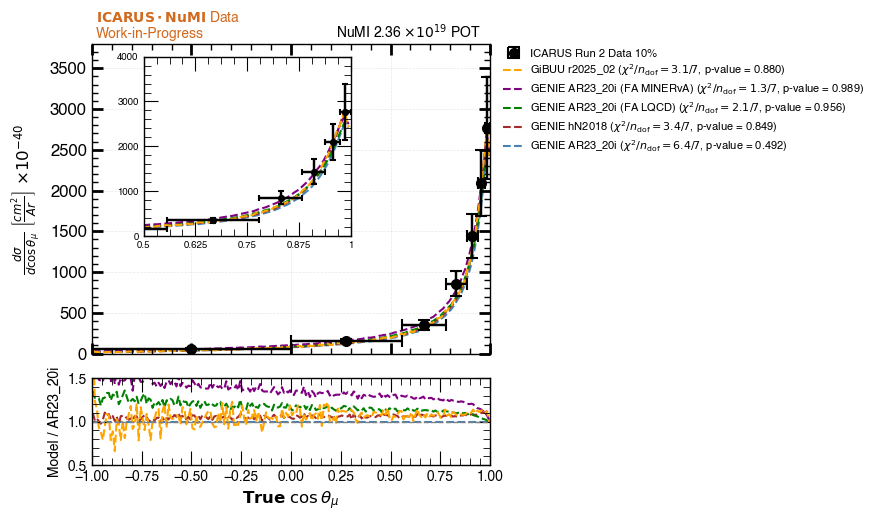

In [12]:
# Overlay GiBUU with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu-14",
    generator_name      = 'GiBUU',
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'GiBUU r2025_02',
    color               = 'orange',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wGiBUU')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           4.072405e+01
  0.0000 – 0.5566           1.350025e+02
  0.5566 – 0.7787           3.116055e+02
  0.7787 – 0.8823           6.269564e+02
  0.8823 – 0.9389           1.157731e+03
  0.9389 – 0.9734           1.900332e+03
  0.9734 – 1.0000           2.361500e+03

χ² / Ndof = 6.6 / 7 = 0.944
p-value = 0.471


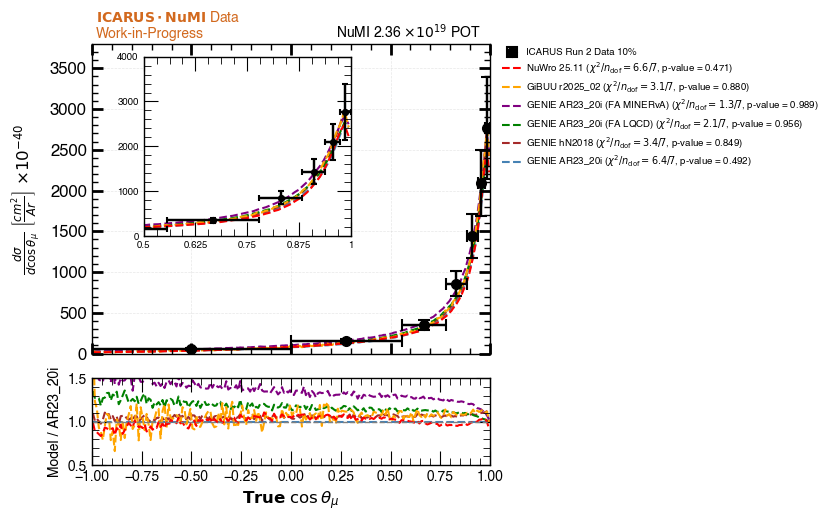

In [13]:
# Overlay NuWro with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu-14",
    generator_name      = 'NuWro',
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'NuWro 25.11',
    color               = 'red',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wNuWro')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_MuonCos)
Bin range                                 xsec
----------------------------------------------------------------------
  -1.0000 – 0.0000           3.541584e+01
  0.0000 – 0.5566           1.256574e+02
  0.5566 – 0.7787           3.114896e+02
  0.7787 – 0.8823           6.500624e+02
  0.8823 – 0.9389           1.225431e+03
  0.9389 – 0.9734           2.046995e+03
  0.9734 – 1.0000           2.757403e+03

χ² / Ndof = 7.2 / 7 = 1.035
p-value = 0.404


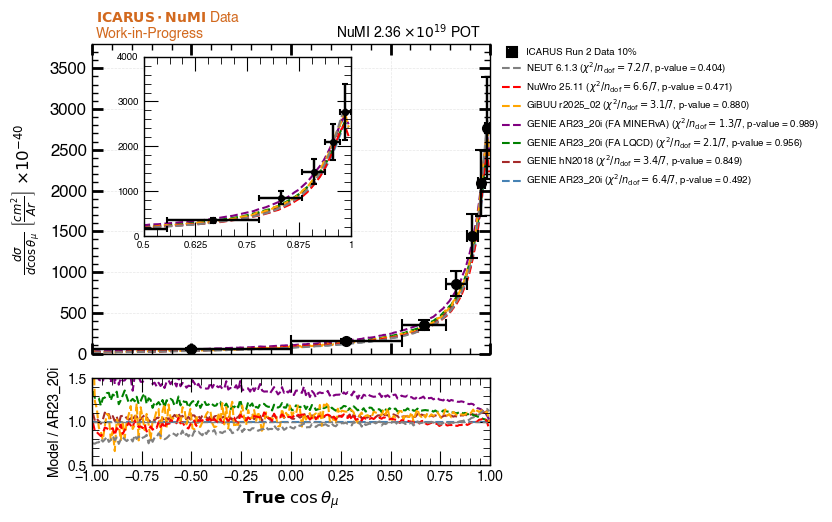

In [14]:
# Overlay NEUT with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu-14",
    generator_name      = 'NEUT',
    bin_edges           = [-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
    nuisance_var        = 'ICARUS_1muNp0pi_MuonCos',
    scaling_power_of_10 = 1e40,
    label               = 'NEUT 6.1.3',
    color               = 'gray',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=200,
    add_ratio=True,
    draw_extracted_ratio=False,
    zoom_range=(0.5, 1.0),   # zoom inset showing cos(theta_mu) in [0.5, 1.0]; the main panel keeps the full range
)
save_fig(fig_genie, r'../Plots/muon_angle/RealData_Containment/XSection', 'muon_angle_XS_wNEUT')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 7 template parameters, shared across all four samples -- not split by containment.

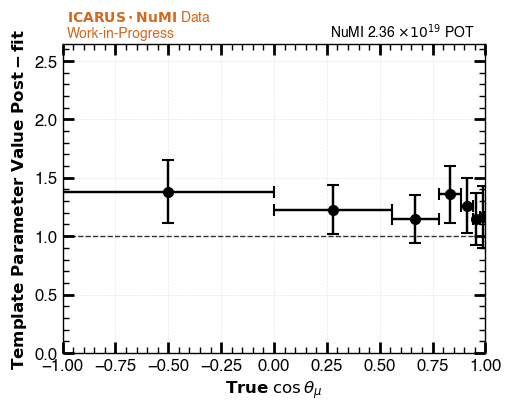

In [15]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_muon_cos_theta_mu/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\cos\theta_{\mu}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[-1.0, 0.0, 0.5566, 0.7787, 0.8823, 0.9389, 0.9734, 1.0],
        remove_last_bin=False,
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI 2.36 $\times 10^{19}$ POT'
)
save_fig(fig_template, r'../Plots/muon_angle/RealData_Containment/TemplateParameters', 'muon_angle')

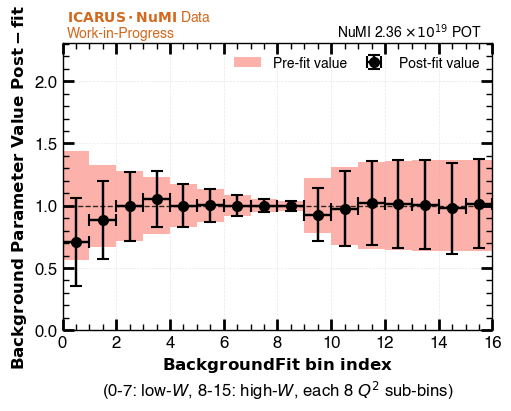

In [16]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/muon_angle/RealData_Containment/BackgroundFitParameters', 'muon_angle')

## Nuisance Parameter Constraints

Interaction-model, flux, and detector systematics -- one set of plots for the whole joint fit, unaffected by the reco-level split.

Number of parameters: 52


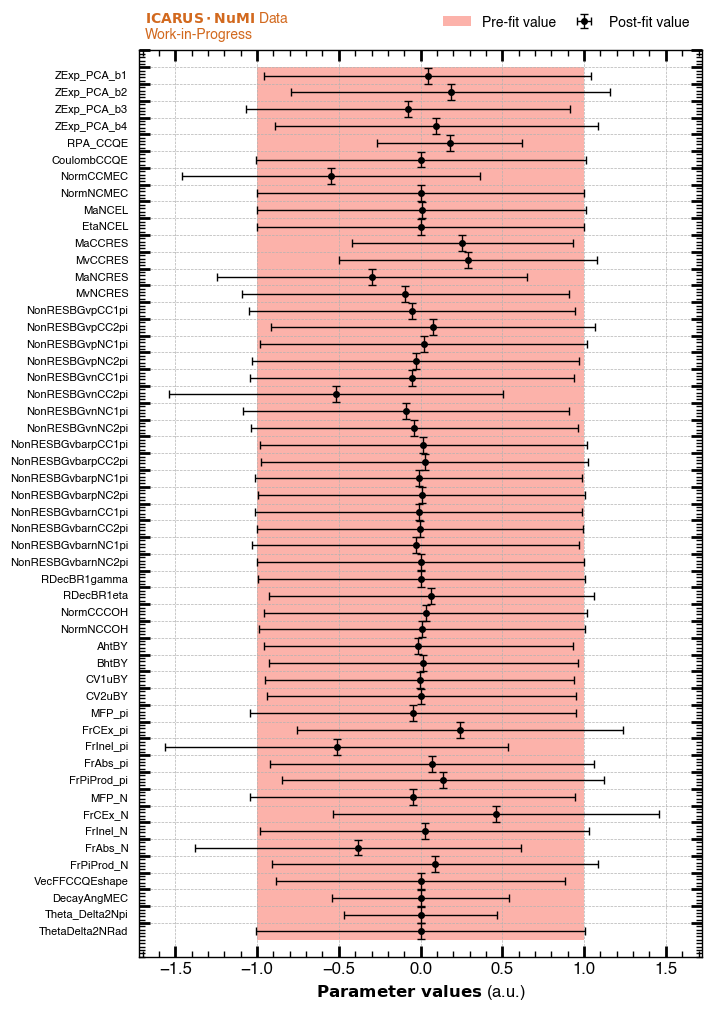

In [17]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 10),
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_InteractionModel')

Number of parameters: 27


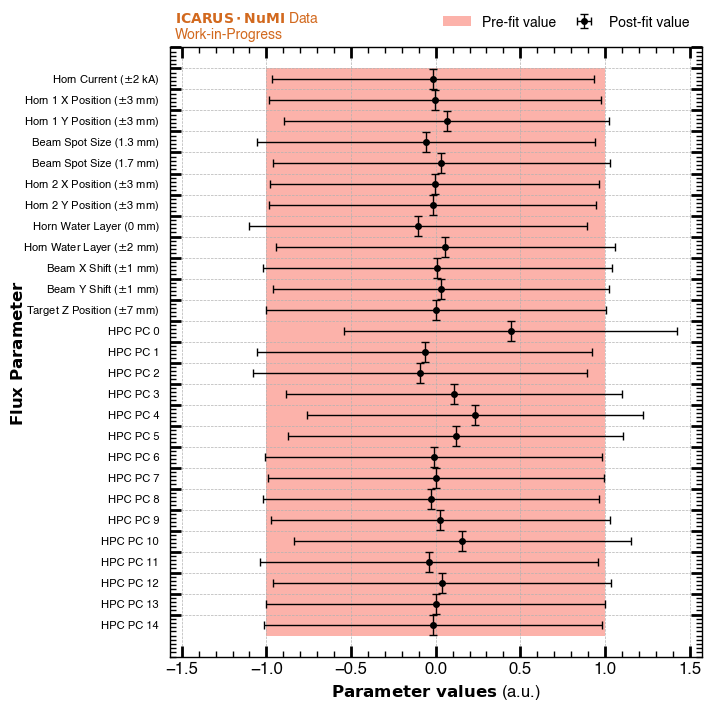

In [18]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_Flux')

Number of parameters: 9


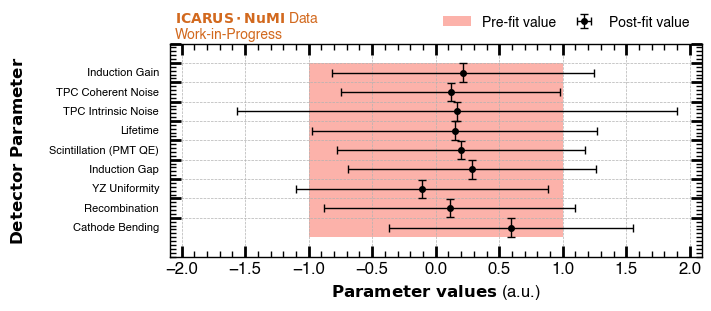

In [19]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_Detector')

Number of parameters: 18


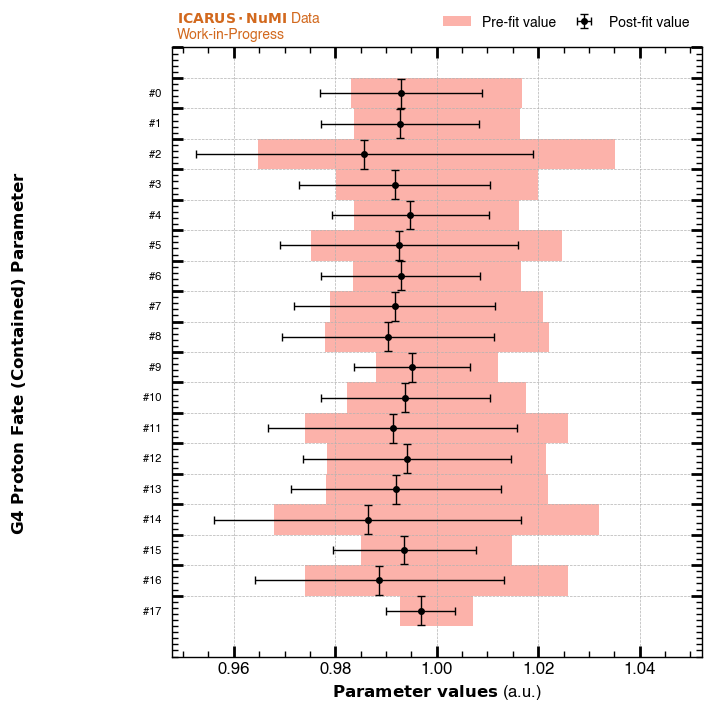

In [20]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (muon-NuMI angle, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_G4_Proton_Contained')

Number of parameters: 14


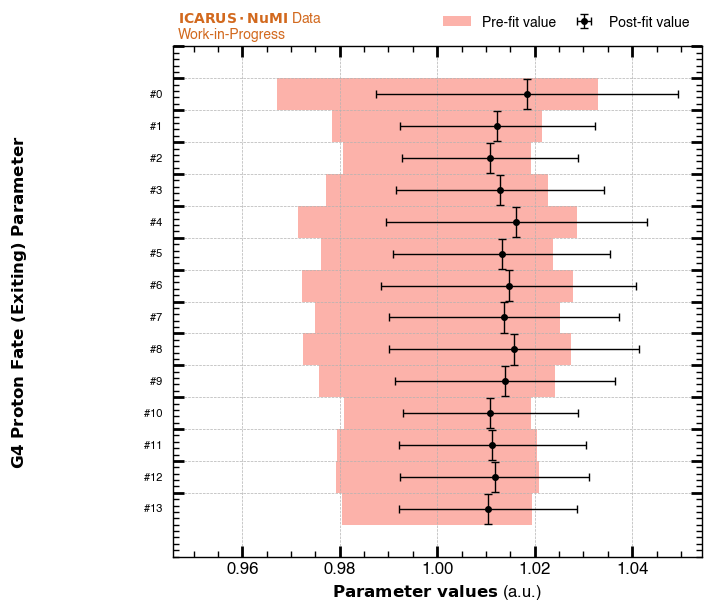

In [21]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 6),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (muon-NuMI angle, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_G4_Proton_Exiting')

Number of parameters: 18


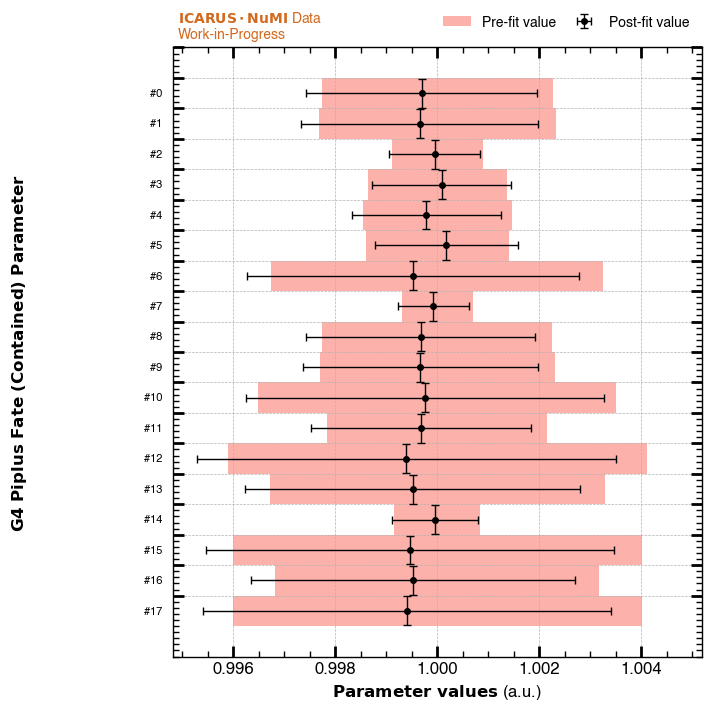

In [22]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (muon-NuMI angle, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_G4_Piplus_Contained')

Number of parameters: 14


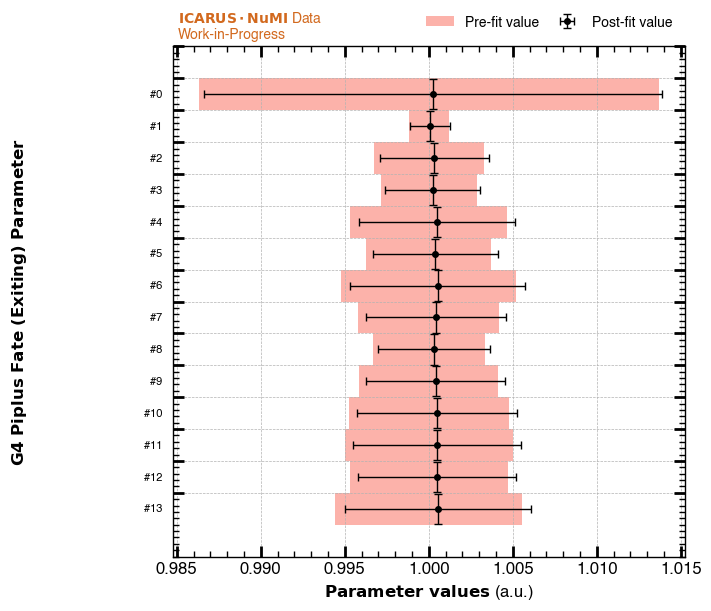

In [23]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 6),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (muon-NuMI angle, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_G4_Piplus_Exiting')

Number of parameters: 18


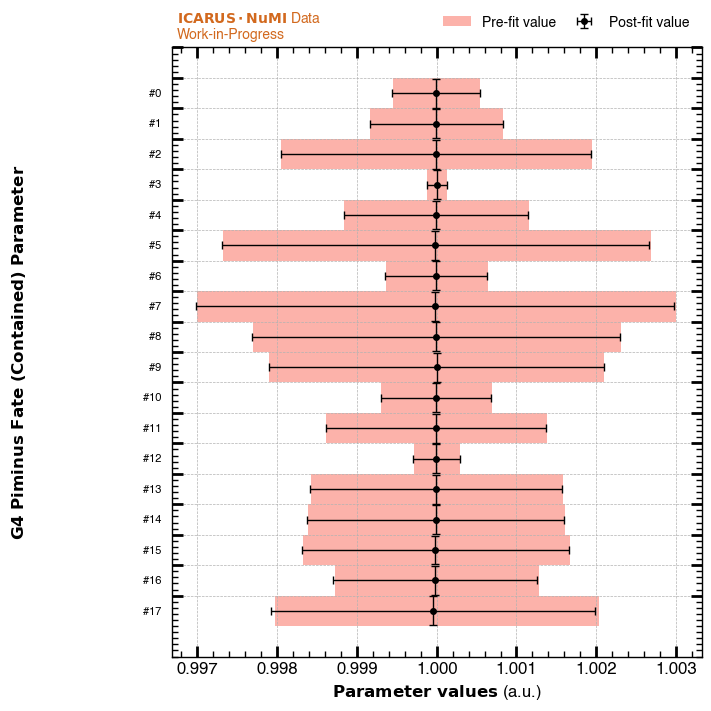

In [24]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (muon-NuMI angle, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_G4_Piminus_Contained')

Number of parameters: 14


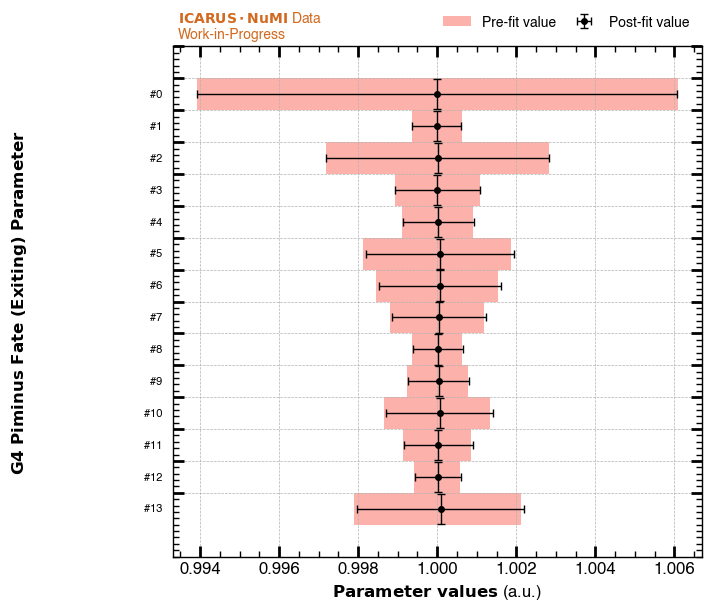

In [25]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root",
    figsize=(7, 6),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (muon-NuMI angle, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/muon_angle/RealData_Containment/NuisanceParameters', 'muon_angle_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices -- among the nuisance parameters themselves, not among reco bins, so `bin_range` stays at its default (full block).

Full matrix size: 52×52


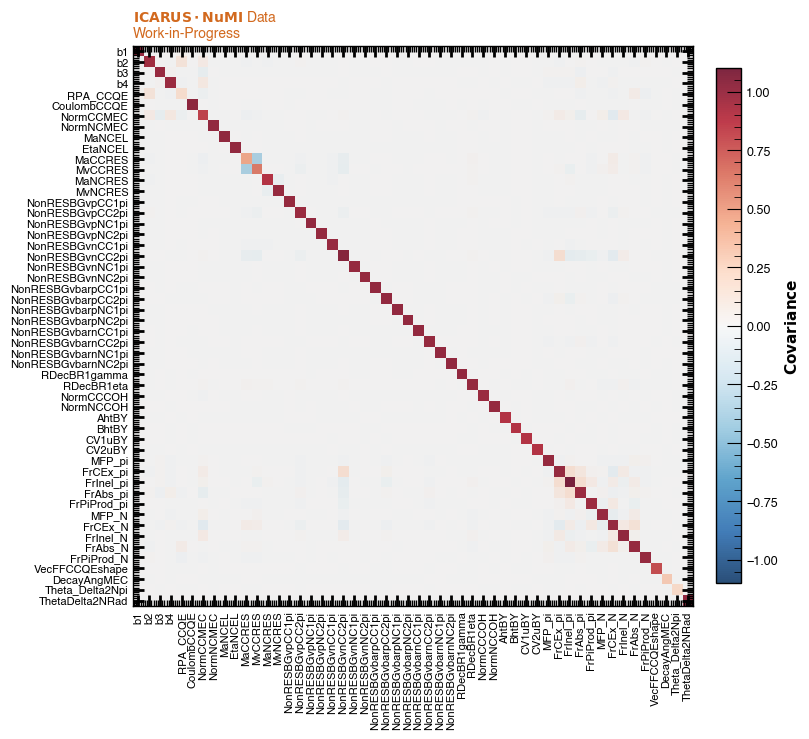

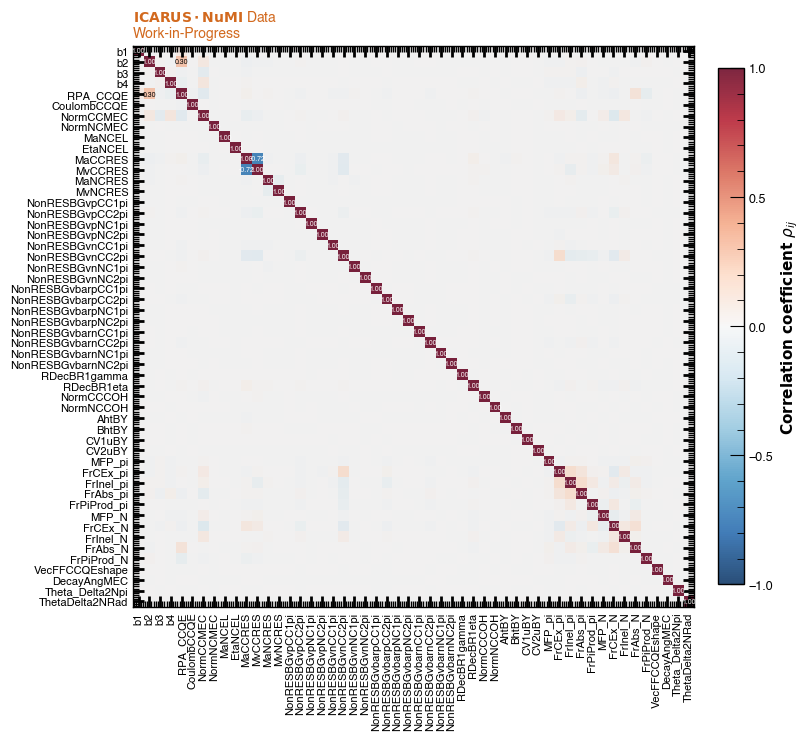

In [26]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(8, 20),
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


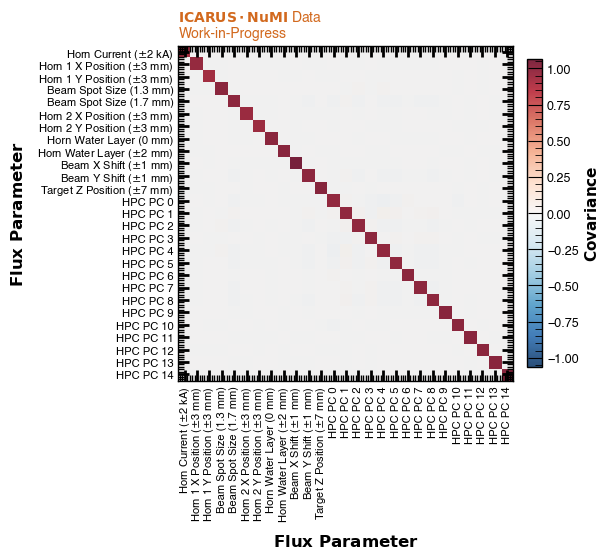

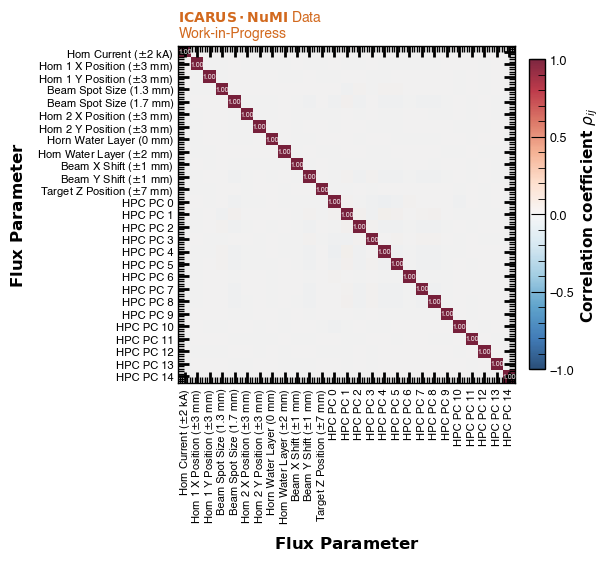

In [27]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


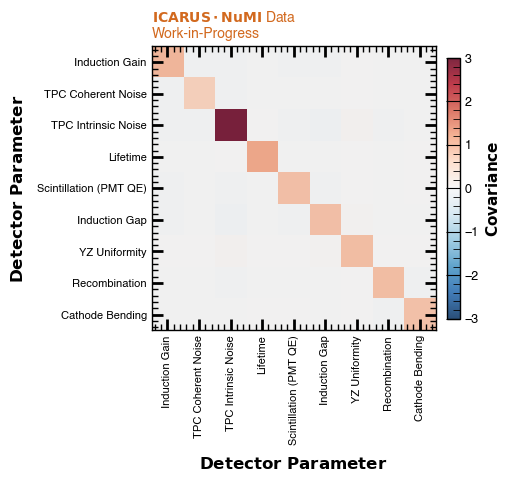

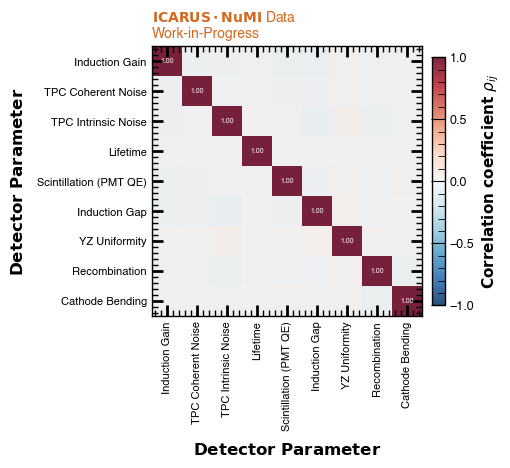

In [28]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'detector_param_correlation')

Full matrix size: 18×18


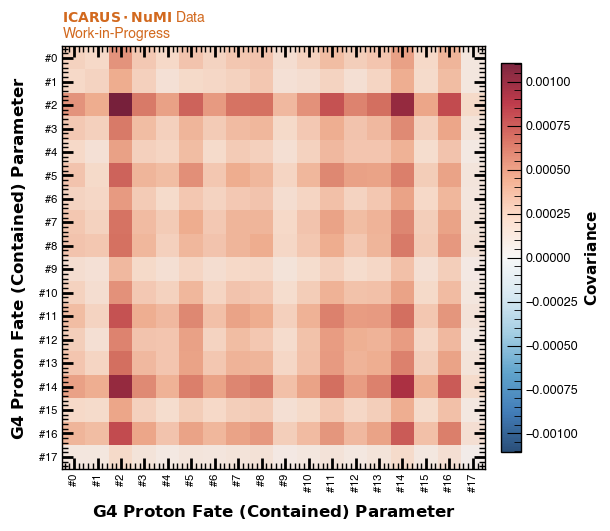

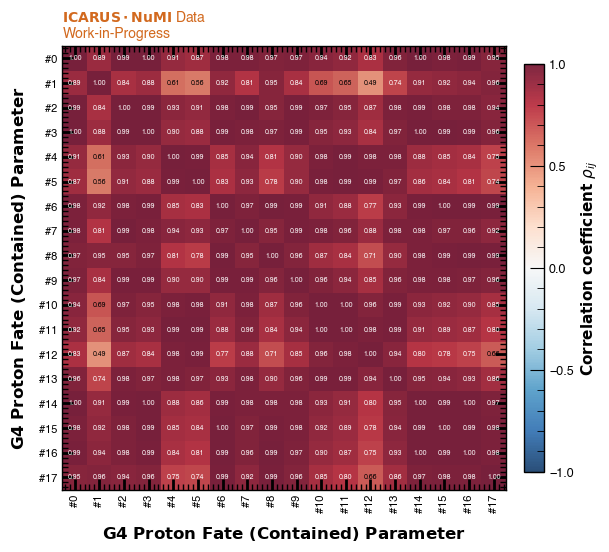

In [29]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (muon-NuMI angle, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (muon-NuMI angle, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 14×14


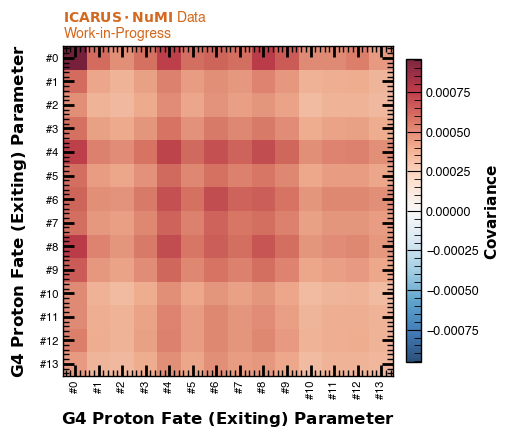

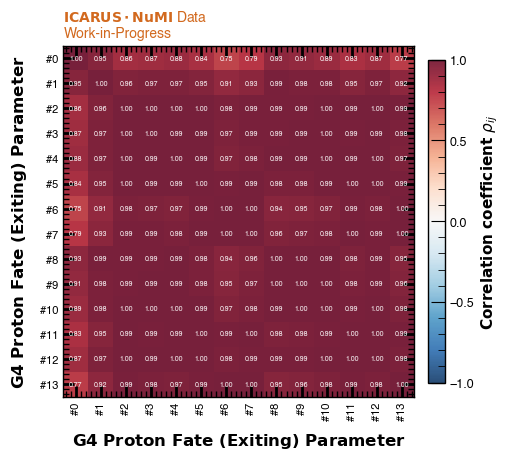

In [30]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(5, 10),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (muon-NuMI angle, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (muon-NuMI angle, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 18×18


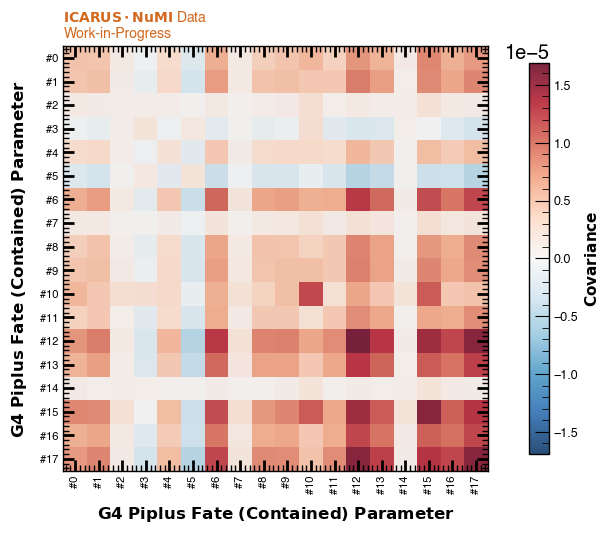

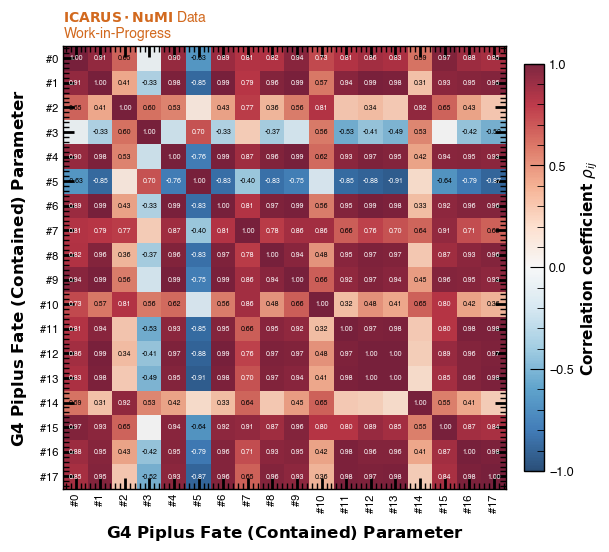

In [31]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (muon-NuMI angle, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (muon-NuMI angle, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 14×14


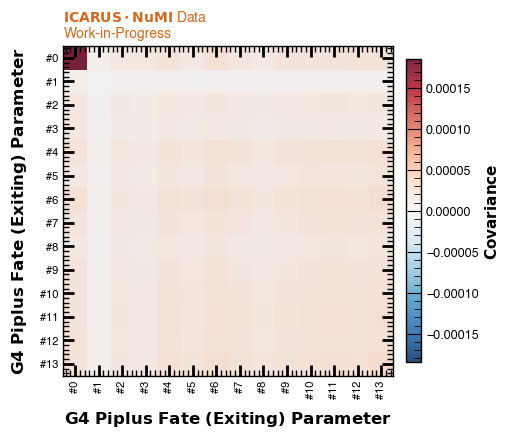

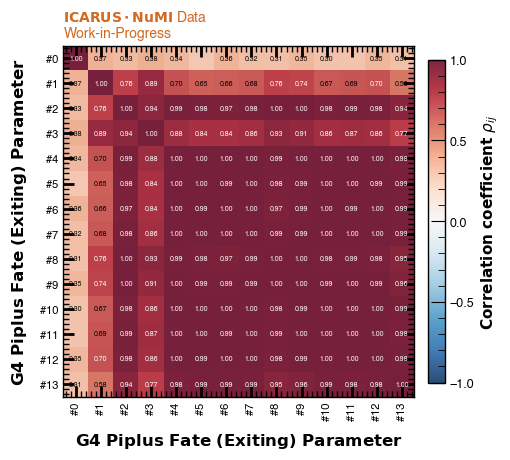

In [32]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(5, 10),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (muon-NuMI angle, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (muon-NuMI angle, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 18×18


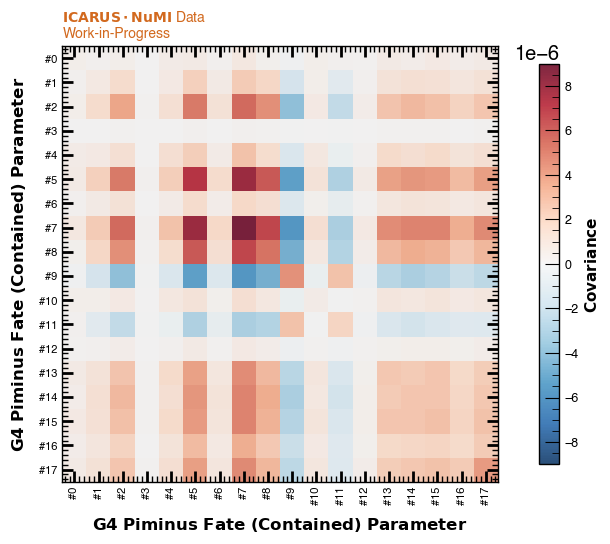

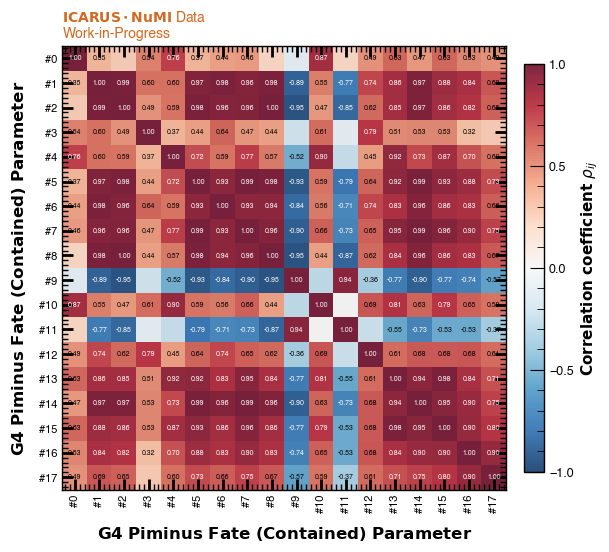

In [33]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (muon-NuMI angle, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (muon-NuMI angle, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 14×14


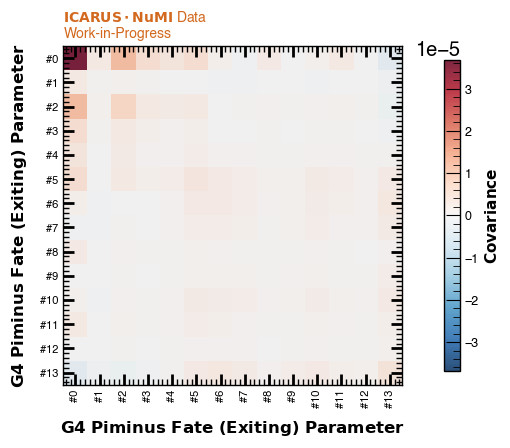

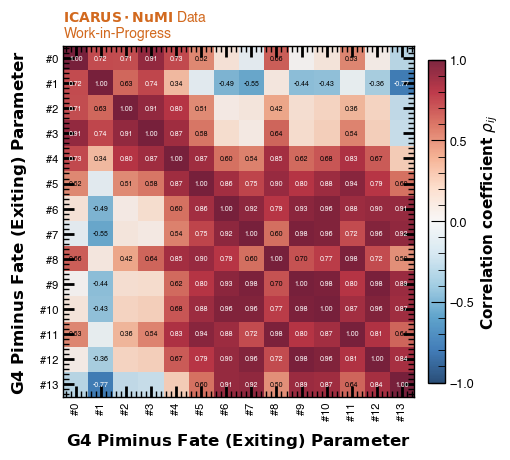

In [34]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(5, 10),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (muon-NuMI angle, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (muon-NuMI angle, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

In [35]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_leading_muon_cos_theta_mu",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (muon-NuMI angle, contained)",
    "G4 Proton Fate (muon-NuMI angle, exiting)",
    "G4 Piplus Fate (muon-NuMI angle, contained)",
    "G4 Piplus Fate (muon-NuMI angle, exiting)",
    "G4 Piminus Fate (muon-NuMI angle, contained)",
    "G4 Piminus Fate (muon-NuMI angle, exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/muon_angle/RealData_Containment/real_containment_muon_angle.root',
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
    show_group_boundaries=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/muon_angle/RealData_Containment/Postfits', 'all_param_correlation')

TypeError: plot_both_matrices() got an unexpected keyword argument 'show_group_boundaries'